# PNV-3421 – Processos Estocásticos
## Aula 09 – ARIMA: Modelo Autorregressivo Integrado com Médias Móveis

Notebook de apoio à aula **"09 - PNV 3421 - ARIMA"**. Segue a mesma sequência dos slides, com os mesmos dados, e usa a **versão atual do `statsmodels`** (`statsmodels.tsa.arima.model.ARIMA`).

**Como usar no Colab:** `Ambiente de execução → Executar tudo`, ou execute as células em ordem com `Shift + Enter`. Todos os dados estão no próprio notebook; não é preciso enviar nenhum arquivo.

**Roteiro**
1. Modelo autorregressivo (AR)
2. Modelo de média móvel (MA)
3. Suavização exponencial × AR × MA
4. Série estacionária: Dickey-Fuller, *detrending* e diferenciação
5. ARIMA e o papel de *d*
6. Como ler a ACF e a PACF
7. Exemplos 2, 3 e 4 (identificação de *p*, *q* e do melhor ARIMA)
8. Resíduos e teste de Ljung-Box-Pierce
9. Treino e teste, e previsão final
10. Sazonalidade: SARIMA
11. Exercícios

**Bibliografia:** Hanke, J.E. & Reitsch, A.G. (1998). *Business Forecasting*, 6th ed. Prentice Hall.

## 0. Configuração

In [1]:
import warnings
from statsmodels.tools.sm_exceptions import EstimationWarning, ConvergenceWarning
for categoria in (UserWarning, FutureWarning, EstimationWarning, ConvergenceWarning):
    warnings.filterwarnings('ignore', category=categoria)   # oculta avisos do otimizador

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

np.set_printoptions(suppress=True, precision=4)
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 100,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('statsmodels', statsmodels.__version__)

statsmodels 0.15.0


In [2]:
# Funções auxiliares usadas ao longo do notebook
def mse(y, f):
    y, f = np.asarray(y), np.asarray(f)
    return np.mean((y - f) ** 2)

def metricas(y, f):
    """RMSE, MAE e MAPE (%) entre valores reais y e previstos f."""
    e = np.asarray(y) - np.asarray(f)
    return {'RMSE': np.sqrt(np.mean(e**2)), 'MAE': np.mean(np.abs(e)),
            'MAPE (%)': 100 * np.mean(np.abs(e / np.asarray(y)))}

def teste_adf(serie, nome='série'):
    """Teste de Dickey-Fuller aumentado. H0: a série NÃO é estacionária."""
    estat, p = adfuller(pd.Series(serie).dropna())[:2]
    conclusao = 'estacionária (rejeita H0)' if p < 0.05 else 'NÃO estacionária (aceita H0)'
    print(f'{nome}: ADF = {estat:.3f}, p-valor = {p:.4f} -> {conclusao}')

def acf_pacf(serie, lags=20, titulo=''):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    plot_acf(serie, lags=lags, ax=ax[0]);  ax[0].set_title(f'ACF {titulo}')
    plot_pacf(serie, lags=lags, ax=ax[1], method='ywm'); ax[1].set_title(f'PACF {titulo}')
    plt.tight_layout(); plt.show()

## 1. Modelo Autorregressivo ("AR")

Um modelo autorregressivo de **p** períodos usa os próprios valores passados como variáveis explicativas:

$$\hat Y_t = \phi_0 + \phi_1 Y_{t-1} + \phi_2 Y_{t-2} + \dots + \phi_p Y_{t-p}, \qquad \epsilon_t = Y_t - \hat Y_t$$

Os coeficientes $\phi$ são obtidos por mínimos quadrados. Exemplo da aula (75 observações):

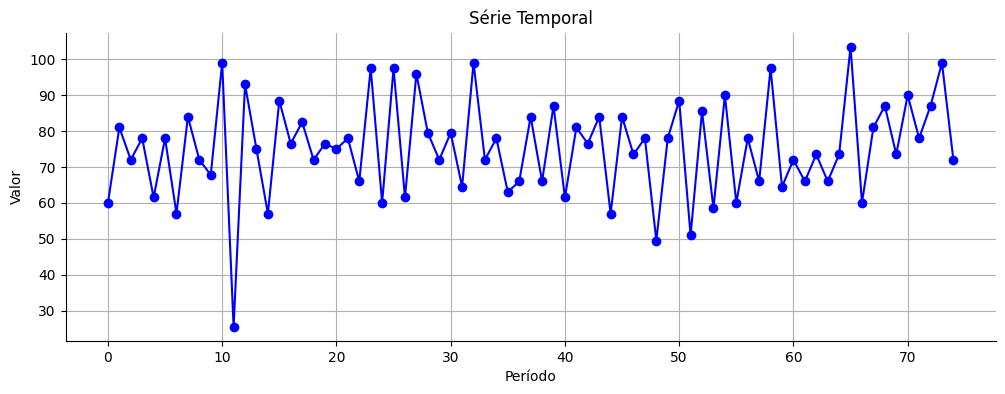

In [3]:
series = np.array([
    60, 81, 72, 78, 61.5, 78, 57, 84, 72, 67.8,
    99, 25.5, 93, 75, 57, 88.5, 76.5, 82.5, 72, 76.5,
    75, 78, 66, 97.5, 60, 97.5, 61.5, 96, 79.5, 72,
    79.5, 64.5, 99, 72, 78, 63, 66, 84, 66, 87,
    61.5, 81, 76.5, 84, 57, 84, 73.5, 78, 49.5, 78,
    88.5, 51, 85.5, 58.5, 90, 60, 78, 66, 97.5, 64.5,
    72, 66, 73.5, 66, 73.5, 103.5, 60, 81, 87, 73.5,
    90, 78, 87, 99, 72])

plt.plot(series, marker='o', linestyle='-', color='b')
plt.title('Série Temporal'); plt.xlabel('Período'); plt.ylabel('Valor'); plt.grid(True)
plt.show()

Parâmetros AR(2): [114.9353  -0.5289   0.0049]
Parâmetros AR(3): [93.3009 -0.5255  0.1101  0.1803]


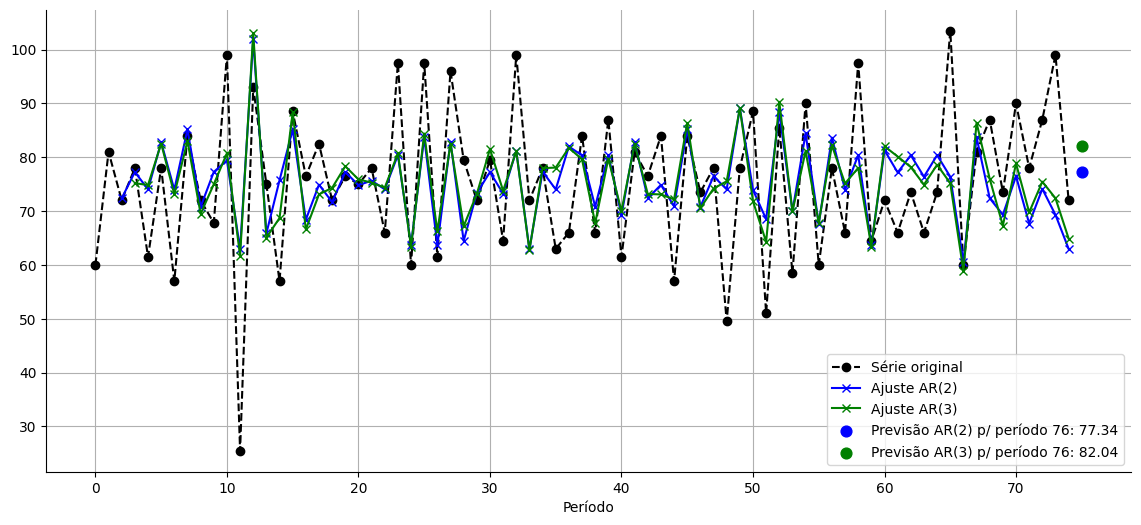

MSE AR(2) = 136.14   MSE AR(3) = 133.98


In [4]:
# Ajuste dos modelos AR(2) e AR(3)
model_ar2 = AutoReg(series, lags=2).fit()
model_ar3 = AutoReg(series, lags=3).fit()
print('Parâmetros AR(2):', model_ar2.params.round(4))
print('Parâmetros AR(3):', model_ar3.params.round(4))

# Valores ajustados (a partir do período p) e previsão para o período 76
fitted_ar2 = model_ar2.predict(start=2, end=len(series) - 1)
fitted_ar3 = model_ar3.predict(start=3, end=len(series) - 1)
prev_ar2 = model_ar2.predict(start=len(series), end=len(series))[0]
prev_ar3 = model_ar3.predict(start=len(series), end=len(series))[0]

plt.figure(figsize=(14, 6))
plt.plot(series, 'ko--', label='Série original')
plt.plot(range(2, len(series)), fitted_ar2, 'b-x', label='Ajuste AR(2)')
plt.plot(range(3, len(series)), fitted_ar3, 'g-x', label='Ajuste AR(3)')
plt.scatter(len(series), prev_ar2, color='b', s=60, label=f'Previsão AR(2) p/ período 76: {prev_ar2:.2f}')
plt.scatter(len(series), prev_ar3, color='g', s=60, label=f'Previsão AR(3) p/ período 76: {prev_ar3:.2f}')
plt.legend(); plt.grid(True); plt.xlabel('Período'); plt.show()

# MSE dentro da amostra (ignora os primeiros p valores, sem previsão)
mse_ar2, mse_ar3 = mse(series[2:], fitted_ar2), mse(series[3:], fitted_ar3)
print(f'MSE AR(2) = {mse_ar2:.2f}   MSE AR(3) = {mse_ar3:.2f}')

## 2. Modelo de Média Móvel ("MA")

Um modelo de média móvel de **q** períodos usa os **erros** (resíduos) passados:

$$\hat Y_t = w_0 + w_1 \epsilon_{t-1} + w_2 \epsilon_{t-2} + \dots + w_q \epsilon_{t-q}$$

No `statsmodels`, um MA(q) é um `ARIMA(order=(0, 0, q))`. Mesmo exemplo anterior:

Parâmetros MA(1): [ 75.2711  -0.3984 148.4466]


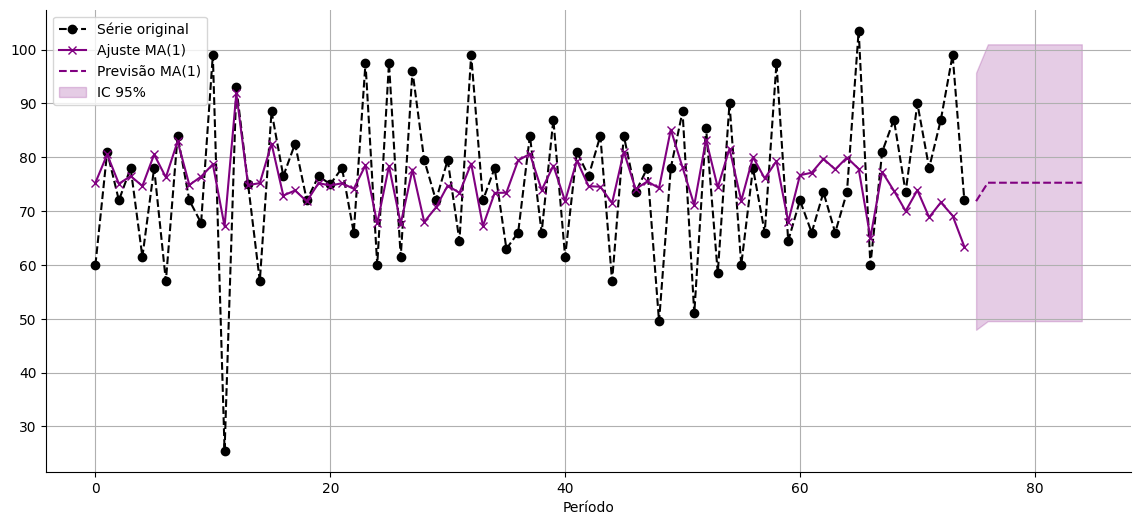

MSE MA(1) = 147.73
Note que, após 1 período, a previsão do MA(1) volta à média w0.


In [5]:
model_ma1 = ARIMA(series, order=(0, 0, 1)).fit()
print('Parâmetros MA(1):', model_ma1.params.round(4))   # const (w0), ma.L1 (w1), sigma2

fitted_ma1 = model_ma1.fittedvalues
prev = model_ma1.get_forecast(steps=10)
ic = prev.conf_int(alpha=0.05)
idx = np.arange(len(series), len(series) + 10)

plt.figure(figsize=(14, 6))
plt.plot(series, 'ko--', label='Série original')
plt.plot(fitted_ma1, color='purple', marker='x', label='Ajuste MA(1)')
plt.plot(idx, prev.predicted_mean, '--', color='purple', label='Previsão MA(1)')
plt.fill_between(idx, ic[:, 0], ic[:, 1], color='purple', alpha=0.2, label='IC 95%')
plt.legend(); plt.grid(True); plt.xlabel('Período'); plt.show()

mse_ma1 = mse(series[1:], fitted_ma1[1:])
print(f'MSE MA(1) = {mse_ma1:.2f}')
print('Note que, após 1 período, a previsão do MA(1) volta à média w0.')

## 3. Suavização Exponencial × AR × MA

**Suavização exponencial simples:** $\hat Y_{t+1} = \alpha Y_t + (1-\alpha)\hat Y_t$. Expandindo a recursão:

$$\hat Y_{t+1} = \alpha Y_t + \alpha(1-\alpha) Y_{t-1} + \alpha(1-\alpha)^2 Y_{t-2} + \dots$$

* **× AR:** parece um AR de ordem infinita, mas com pesos **fixos** (positivos, decrescentes, somam 1, governados por um só α). No AR(p) os pesos são **livres** e podem ser negativos.
* **× MA:** escrevendo $\hat Y_{t+1} = \hat Y_t + \alpha\,\epsilon_t$, obtém-se $Y_{t+1} - Y_t = \epsilon_{t+1} - (1-\alpha)\epsilon_t$, isto é, a suavização exponencial é um **ARIMA(0,1,1)**, um MA(1) da série **diferenciada**, com $\theta = -(1-\alpha)$.

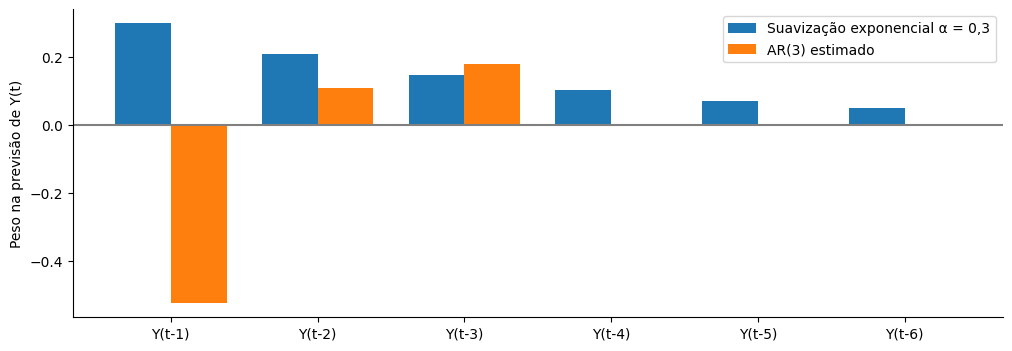

phi_1 do AR(3) = -0.526 -> correlação negativa: nenhum α reproduz isso.


In [6]:
# Pesos de cada valor passado na previsão: suavização (α = 0,3) × AR(3) estimado
lags = np.arange(1, 7)
alpha = 0.3
pesos_ses = alpha * (1 - alpha) ** (lags - 1)
pesos_ar3 = np.r_[model_ar3.params[1:], [0, 0, 0]]

w = 0.38
plt.bar(lags - w/2, pesos_ses, w, label='Suavização exponencial α = 0,3')
plt.bar(lags + w/2, pesos_ar3, w, label='AR(3) estimado')
plt.axhline(0, color='gray'); plt.xticks(lags, [f'Y(t-{k})' for k in lags])
plt.ylabel('Peso na previsão de Y(t)'); plt.legend(); plt.show()
print('phi_1 do AR(3) =', round(model_ar3.params[1], 3), '-> correlação negativa: nenhum α reproduz isso.')

In [7]:
# Suavização exponencial com α ótimo e com α = 0,3
ses_otimo = SimpleExpSmoothing(series, initialization_method='estimated').fit()
ses_03 = SimpleExpSmoothing(series, initialization_method='known',
                            initial_level=series[0]).fit(smoothing_level=0.3, optimized=False)
print(f"α ótimo = {ses_otimo.params['smoothing_level']:.4f}  (≈ 0: a suavização vira a média {series.mean():.1f})")

# Equivalência com ARIMA(0,1,1): α = 1 + θ
arima011 = ARIMA(series, order=(0, 1, 1)).fit()
theta = arima011.params[0]
print(f'ARIMA(0,1,1): θ = {theta:.3f}  ->  α = 1 + θ = {1 + theta:.3f}')

tabela = pd.DataFrame({'MSE': [mse(series[1:], ses_otimo.fittedvalues[1:]),
                               mse(series[1:], ses_03.fittedvalues[1:]),
                               mse_ma1, mse_ar2, mse_ar3]},
                      index=['Suav. exp. (α ótimo ≈ 0)', 'Suav. exp. (α = 0,3)', 'MA(1)', 'AR(2)', 'AR(3)'])
display(tabela.round(1))

α ótimo = 0.0000  (≈ 0: a suavização vira a média 75.2)
ARIMA(0,1,1): θ = -0.997  ->  α = 1 + θ = 0.003


,MSE
Suav. exp. (α ótimo ≈ 0),187.7
"Suav. exp. (α = 0,3)",246.9
MA(1),147.7
AR(2),136.1
AR(3),134.0


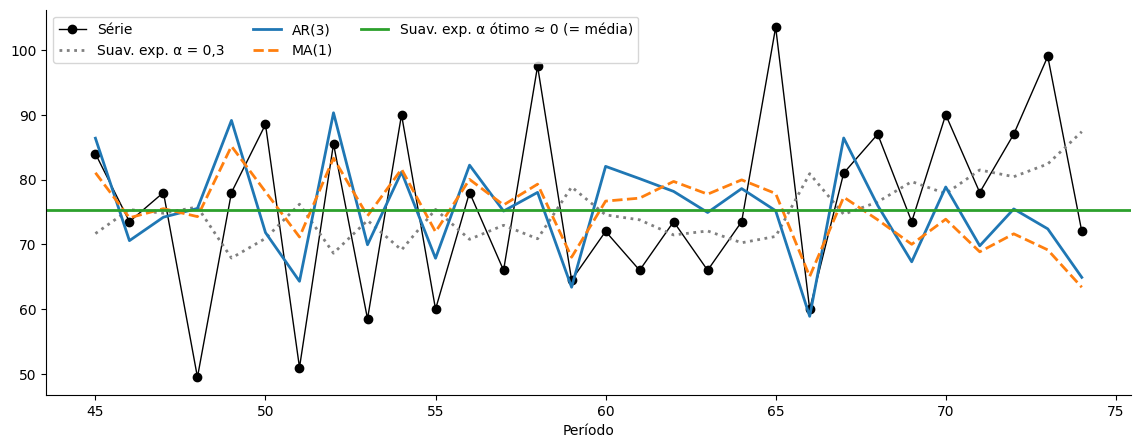

In [8]:
k = 45   # mostra os últimos 30 períodos
t = np.arange(len(series))
plt.figure(figsize=(14, 5))
plt.plot(t[k:], series[k:], 'ko-', lw=1, label='Série')
plt.plot(t[k:], ses_03.fittedvalues[k:], ':', color='gray', lw=2, label='Suav. exp. α = 0,3')
plt.plot(t[k:], model_ar3.fittedvalues[k-3:], color='tab:blue', lw=2, label='AR(3)')
plt.plot(t[k:], fitted_ma1[k:], '--', color='tab:orange', lw=2, label='MA(1)')
plt.axhline(series.mean(), color='tab:green', lw=2, label='Suav. exp. α ótimo ≈ 0 (= média)')
plt.legend(ncol=3); plt.xlabel('Período'); plt.show()

**Conclusão:** nesta série os valores vizinhos são correlacionados **negativamente** (zigue-zague). A suavização exponencial só sabe "seguir o nível"; o melhor que consegue é ignorar o histórico (α → 0). AR e MA usam essa correlação e reduzem o erro em ~25%.

## 4. ARMA e Série Estacionária

**ARMA(p,q):** $\hat Y_t = \theta_0 + \sum_{i=1}^{p}\phi_i Y_{t-i} + \sum_{i=1}^{q} w_i \epsilon_{t-i}$.

AR, MA e ARMA supõem série **estacionária** (média e variância constantes). Verificamos com o **teste de Dickey-Fuller** (H0: série não estacionária). Exemplo da aula (demanda semanal):

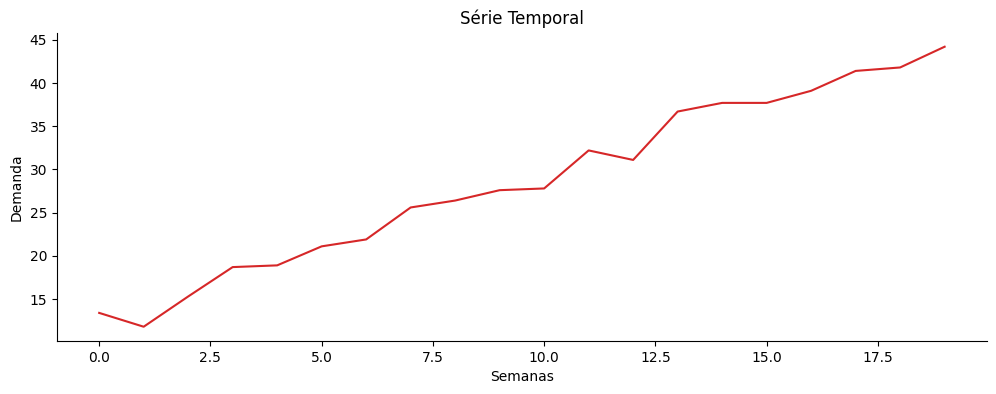

Série original: ADF = 8.681, p-valor = 1.0000 -> NÃO estacionária (aceita H0)


In [9]:
data1 = [
    13.4, 11.8, 15.3, 18.7, 18.9, 21.1, 21.9, 25.6, 26.4, 27.6,
    27.8, 32.2, 31.1, 36.7, 37.7, 37.7, 39.1, 41.4, 41.8, 44.2]
df1 = pd.DataFrame({'Yt': data1})

plt.plot(df1.index, df1.Yt, color='tab:red')
plt.gca().set(title='Série Temporal', xlabel='Semanas', ylabel='Demanda'); plt.show()

teste_adf(df1.Yt, 'Série original')

Duas formas de torná-la estacionária:
* **Detrending:** remover a tendência ajustada por regressão ($\hat Y_t = 10 + 1{,}78\,t$ nos slides);
* **Differencing:** $Y_t - Y_{t-1}$ (repetir *d* vezes se necessário).

Tendência por mínimos quadrados: Y = 10.70 + 1.70 t   (slide: Y = 10 + 1,78 t)
Série sem tendência: [11.6, 8.2, 10.0, 11.6, 10.0, 10.4, 9.4, 11.4, 10.4, 9.8, 8.2, 10.8, 8.0, 11.8, 11.0, 9.2, 8.8, 9.4, 8.0, 8.6]


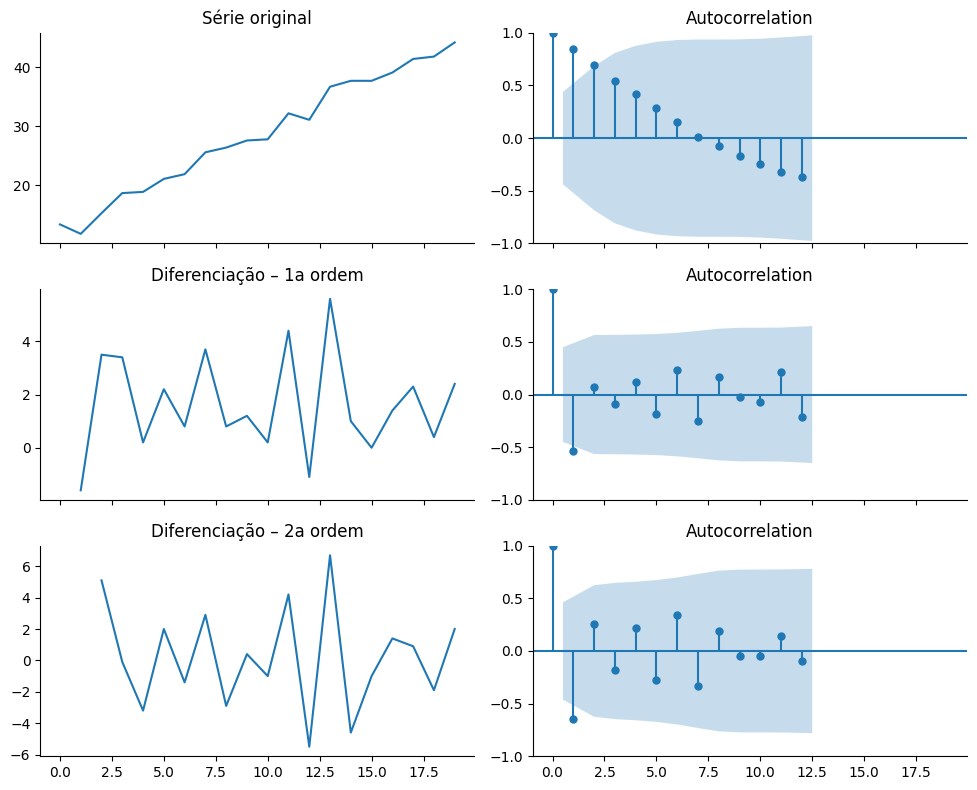

Sem tendência (detrending): ADF = -4.144, p-valor = 0.0008 -> estacionária (rejeita H0)
1a diferença: ADF = -2.993, p-valor = 0.0355 -> estacionária (rejeita H0)


In [10]:
t = np.arange(1, len(df1) + 1)
b1, b0 = np.polyfit(t, df1.Yt, 1)
print(f'Tendência por mínimos quadrados: Y = {b0:.2f} + {b1:.2f} t   (slide: Y = 10 + 1,78 t)')
sem_tendencia = df1.Yt - 1.78 * t                  # detrending como no slide (11,6; 8,2; 10,0; ...)
print('Série sem tendência:', sem_tendencia.round(1).tolist())

fig, axes = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
for i, (s, nome) in enumerate([(df1.Yt, 'Série original'),
                               (df1.Yt.diff(), 'Diferenciação – 1a ordem'),
                               (df1.Yt.diff().diff(), 'Diferenciação – 2a ordem')]):
    axes[i, 0].plot(s); axes[i, 0].set_title(nome)
    plot_acf(s.dropna(), ax=axes[i, 1], lags=12)
plt.tight_layout(); plt.show()

teste_adf(sem_tendencia, 'Sem tendência (detrending)')
teste_adf(df1.Yt.diff(), '1a diferença')

> **Cuidado com amostras pequenas:** com só 20 observações, o ADF com escolha automática de defasagens é instável (pequenas mudanças na série alteram muito o p-valor). Use-o junto com o gráfico e a ACF, não isoladamente.

## 5. ARIMA(p,d,q) e o papel de *d*

No ARIMA, os termos AR e MA se aplicam à série **diferenciada *d* vezes**, $W_t$:

* $d=0$: $W_t = Y_t$  $d=1$: $W_t = Y_t - Y_{t-1}$  $d=2$: $W_t = (Y_t - Y_{t-1}) - (Y_{t-1} - Y_{t-2})$

$$\hat W_t = \theta_0 + \sum \phi_i W_{t-i} + \sum w_i \epsilon_{t-i}$$

A previsão em nível é obtida "integrando" de volta: $\hat Y_t = Y_{t-1} + \hat W_t$. No `statsmodels` isso é automático: basta passar a série original e `order=(p, d, q)`. Com $d \ge 1$, a constante (variação média por período, *drift*) só entra com `trend='t'`.

## 6. Como ler a ACF e a PACF

* **ACF(k):** correlação entre $Y_t$ e $Y_{t-k}$. **PACF(k):** a mesma correlação, descontado o efeito das defasagens intermediárias.
* Faixa azul: intervalo de 95% sob correlação nula (≈ ±1,96/√n). Barra dentro da faixa → não significativa.

| | AR(p) | MA(q) | ARMA(p,q) |
|---|---|---|---|
| **ACF** | decai | **corta após q** | decai |
| **PACF** | **corta após p** | decai | decai |

**Por quê?** No AR(1), $Y_t$ depende diretamente só de $Y_{t-1}$; a correlação com defasagens maiores é indireta e vai se diluindo (ACF = $\phi^k$). A PACF remove os efeitos indiretos → zero após *p*. No MA(1), $Y_t$ e $Y_{t-2}$ não compartilham nenhum choque ε → ACF zero após *q*.

Padrões típicos com séries simuladas:

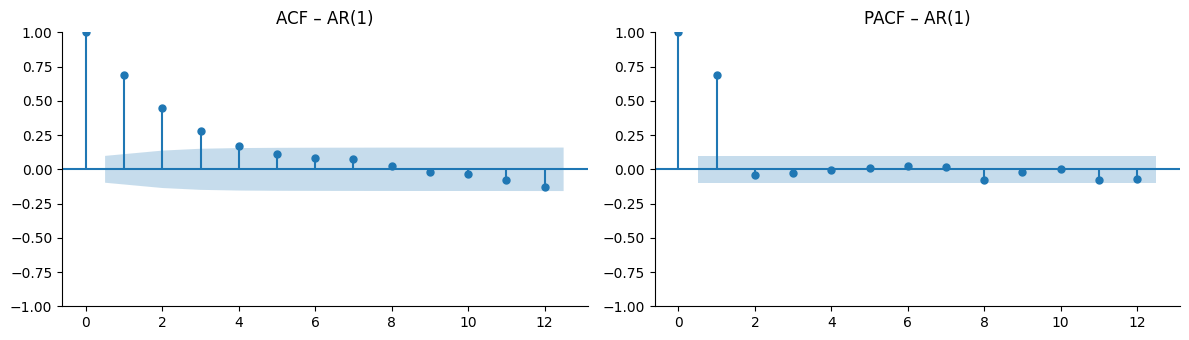

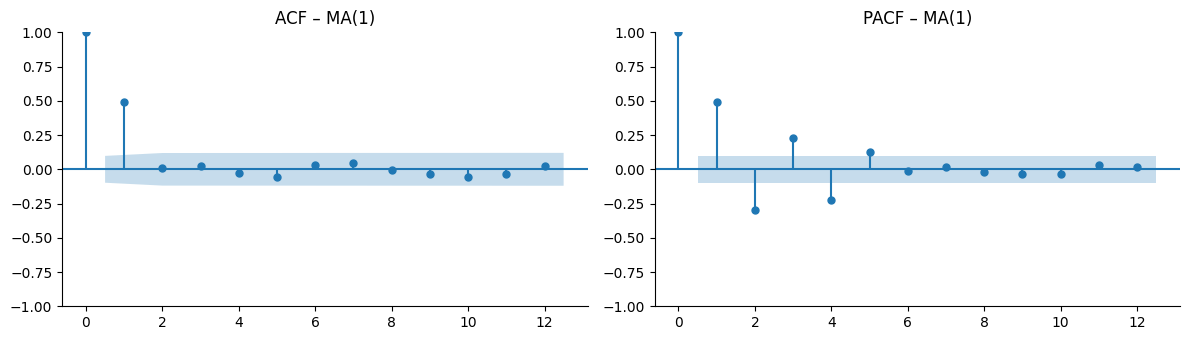

In [11]:
np.random.seed(27)
ar1 = ArmaProcess([1, -0.7], [1]).generate_sample(400)   # Y_t = 0,7 Y_{t-1} + e_t
ma1 = ArmaProcess([1], [1, 0.7]).generate_sample(400)    # Y_t = e_t + 0,7 e_{t-1}
acf_pacf(ar1, lags=12, titulo='– AR(1)')
acf_pacf(ma1, lags=12, titulo='– MA(1)')

**Experimente:** troque os coeficientes (ex.: `[1, -0.5, -0.3]` para um AR(2)) e veja onde a PACF corta. Com amostras finitas, uma barra isolada pode sair da faixa por acaso (≈ 1 em 20): observe o padrão.

## 7. ARIMA – Exemplo 2: determinar *p* (modelo autorregressivo)

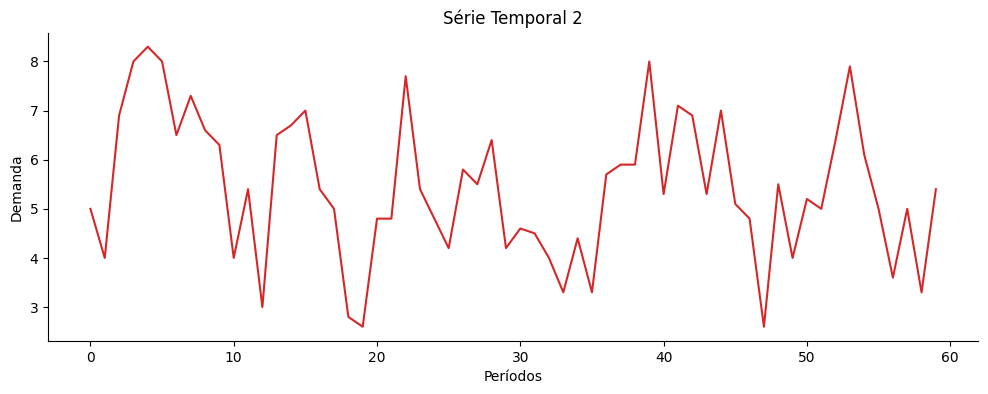

Série 2: ADF = -4.147, p-valor = 0.0008 -> estacionária (rejeita H0)


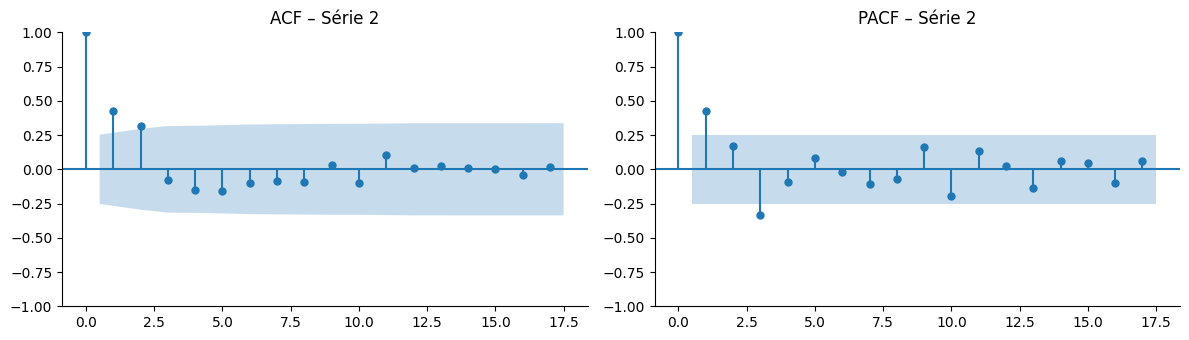

In [12]:
data2 = [
    5, 4, 6.9, 8, 8.3, 8, 6.5, 7.3, 6.6, 6.3,
    4, 5.4, 3, 6.5, 6.7, 7, 5.4, 5, 2.8, 2.6,
    4.8, 4.8, 7.7, 5.4, 4.8, 4.2, 5.8, 5.5, 6.4, 4.2,
    4.6, 4.5, 4, 3.3, 4.4, 3.3, 5.7, 5.9, 5.9, 8,
    5.3, 7.1, 6.9, 5.3, 7, 5.1, 4.8, 2.6, 5.5, 4,
    5.2, 5, 6.4, 7.9, 6.1, 5, 3.6, 5, 3.3, 5.4]
df2 = pd.DataFrame({'Yt': data2})

plt.plot(df2.index, df2.Yt, color='tab:red')
plt.gca().set(title='Série Temporal 2', xlabel='Períodos', ylabel='Demanda'); plt.show()
teste_adf(df2.Yt, 'Série 2')
acf_pacf(df2.Yt, lags=17, titulo='– Série 2')

In [13]:
# PACF significativa até a defasagem 3 -> AR(3)
ar3_ex2 = AutoReg(df2.Yt, lags=3).fit()
print(ar3_ex2.params.round(4))
c = ar3_ex2.params.values
print(f'Y = {c[0]:.2f} + {c[1]:.2f} Y(t-1) + {c[2]:.2f} Y(t-2) + {c[3]:.2f} Y(t-3)')

const    3.3720
Yt.L1    0.4313
Yt.L2    0.3044
Yt.L3   -0.3593
dtype: float64
Y = 3.37 + 0.43 Y(t-1) + 0.30 Y(t-2) + -0.36 Y(t-3)


> **Observação:** com os dados da tabela, os mínimos quadrados resultam em $\hat Y_t = 3{,}37 + 0{,}43Y_{t-1} + 0{,}30Y_{t-2} - 0{,}36Y_{t-3}$, diferente dos coeficientes mostrados no slide (3 + 0,63; 0,27; −0,40). A ordem do modelo, 3, é a mesma.

## 7. ARIMA – Exemplo 3: determinar *q* (modelo de média móvel)

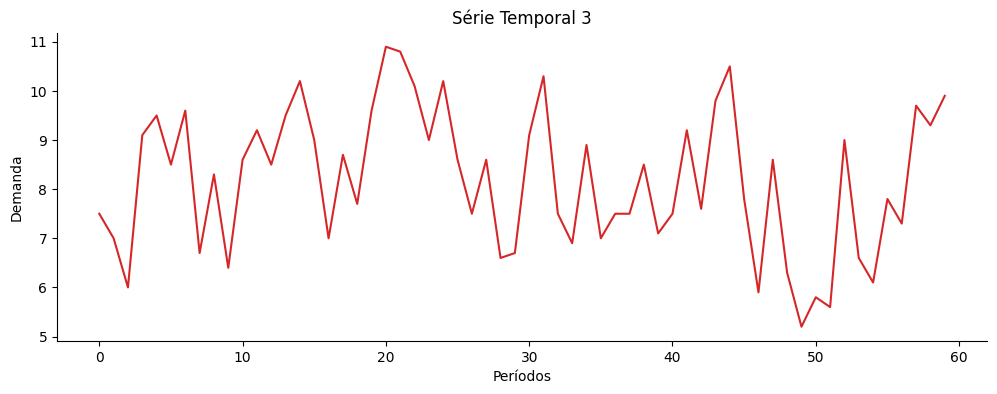

Série 3: ADF = -4.984, p-valor = 0.0000 -> estacionária (rejeita H0)


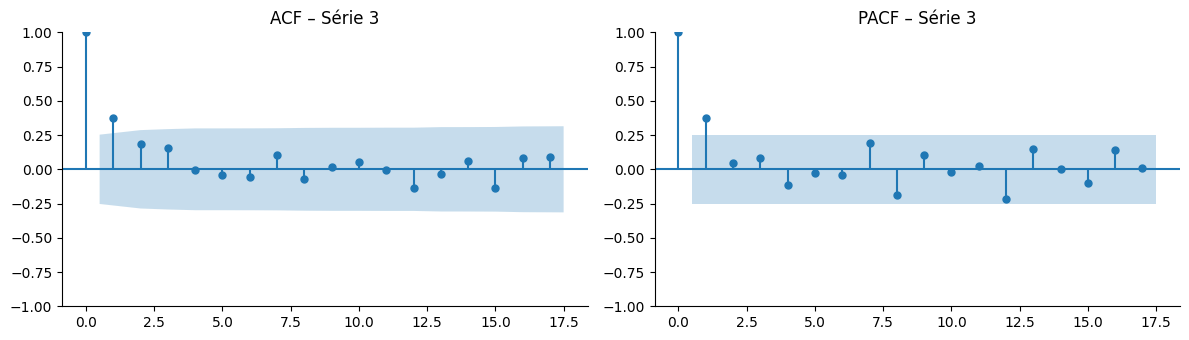

In [14]:
data3 = [
    7.5, 7, 6, 9.1, 9.5, 8.5, 9.6, 6.7, 8.3, 6.4,
    8.6, 9.2, 8.5, 9.5, 10.2, 9, 7, 8.7, 7.7, 9.6,
    10.9, 10.8, 10.1, 9, 10.2, 8.6, 7.5, 8.6, 6.6, 6.7,
    9.1, 10.3, 7.5, 6.9, 8.9, 7, 7.5, 7.5, 8.5, 7.1,
    7.5, 9.2, 7.6, 9.8, 10.5, 7.8, 5.9, 8.6, 6.3, 5.2,
    5.8, 5.6, 9, 6.6, 6.1, 7.8, 7.3, 9.7, 9.3, 9.9]
df3 = pd.DataFrame({'Yt': data3})

plt.plot(df3.index, df3.Yt, color='tab:red')
plt.gca().set(title='Série Temporal 3', xlabel='Períodos', ylabel='Demanda'); plt.show()
teste_adf(df3.Yt, 'Série 3')
acf_pacf(df3.Yt, lags=17, titulo='– Série 3')

In [15]:
# ACF significativa só na defasagem 1 -> MA(1)
ma1_ex3 = ARIMA(df3.Yt, order=(0, 0, 1)).fit()
print(ma1_ex3.params.round(4))
print(f"Y = {ma1_ex3.params['const']:.4f} + {ma1_ex3.params['ma.L1']:.4f} e(t-1)")

const     8.1957
ma.L1     0.3523
sigma2    1.7948
dtype: float64
Y = 8.1957 + 0.3523 e(t-1)


## 7. ARIMA – Exemplo 4: determinar o melhor modelo ARIMA (Box-Jenkins)

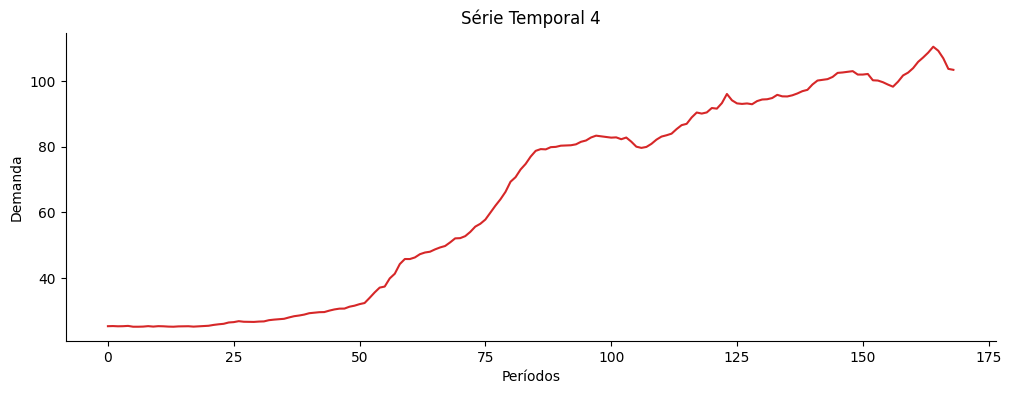

Série 4: ADF = -0.775, p-valor = 0.8265 -> NÃO estacionária (aceita H0)


In [16]:
data4 = [
    25.4, 25.44, 25.37, 25.4, 25.49, 25.24, 25.24, 25.28, 25.42, 25.28,
    25.41, 25.37, 25.28, 25.24, 25.34, 25.36, 25.39, 25.27, 25.35, 25.42,
    25.53, 25.79, 25.98, 26.13, 26.53, 26.64, 26.93, 26.75, 26.74, 26.7,
    26.81, 26.86, 27.23, 27.4, 27.51, 27.65, 28.07, 28.44, 28.65, 28.93,
    29.35, 29.49, 29.66, 29.7, 30.14, 30.5, 30.74, 30.76, 31.33, 31.64,
    32.11, 32.45, 34.02, 35.67, 37.14, 37.46, 39.94, 41.36, 44.3, 45.84,
    45.83, 46.32, 47.31, 47.82, 48.06, 48.77, 49.36, 49.8, 50.9, 52.12,
    52.19, 52.8, 54.08, 55.7, 56.56, 57.84, 59.94, 62.07, 64.01, 66.27,
    69.35, 70.74, 73.08, 74.77, 77, 78.75, 79.28, 79.2, 79.87, 79.96,
    80.32, 80.4, 80.45, 80.73, 81.5, 81.9, 82.82, 83.37, 83.17, 82.96,
    82.77, 82.85, 82.29, 82.8, 81.54, 80.02, 79.65, 79.94, 80.88, 82.16,
    83.09, 83.49, 83.98, 85.37, 86.57, 86.97, 88.92, 90.41, 90.09, 90.44,
    91.78, 91.59, 93.27, 96.05, 94.13, 93.19, 93.03, 93.17, 92.93, 93.89,
    94.37, 94.45, 94.82, 95.79, 95.33, 95.3, 95.65, 96.21, 96.91, 97.31,
    98.94, 100.14, 100.35, 100.57, 101.24, 102.47, 102.6, 102.81, 103, 101.96,
    101.96, 102.14, 100.22, 100.14, 99.63, 98.91, 98.27, 99.79, 101.69, 102.55,
    103.91, 105.83, 107.17, 108.64, 110.43, 109.2, 106.9, 103.69, 103.4]
df4 = pd.DataFrame({'Yt': data4})

plt.plot(df4.index, df4.Yt, color='tab:red')
plt.gca().set(title='Série Temporal 4', xlabel='Períodos', ylabel='Demanda'); plt.show()
teste_adf(df4.Yt, 'Série 4')

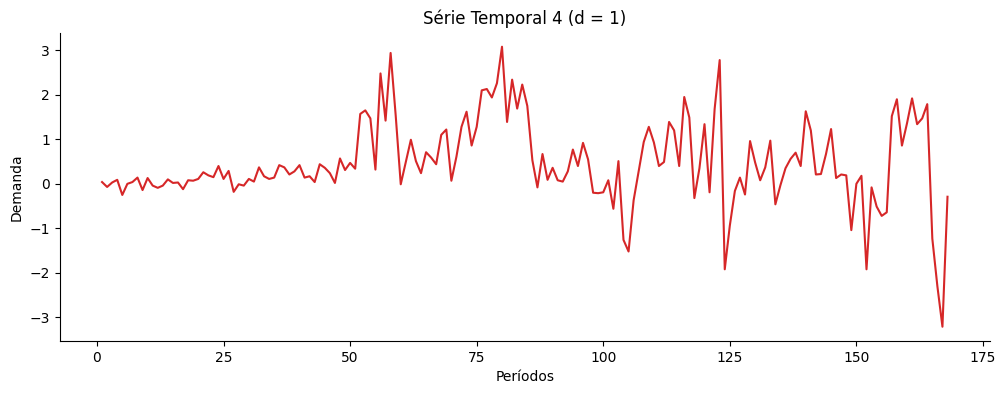

Série 4, 1a diferença: ADF = -4.048, p-valor = 0.0012 -> estacionária (rejeita H0)


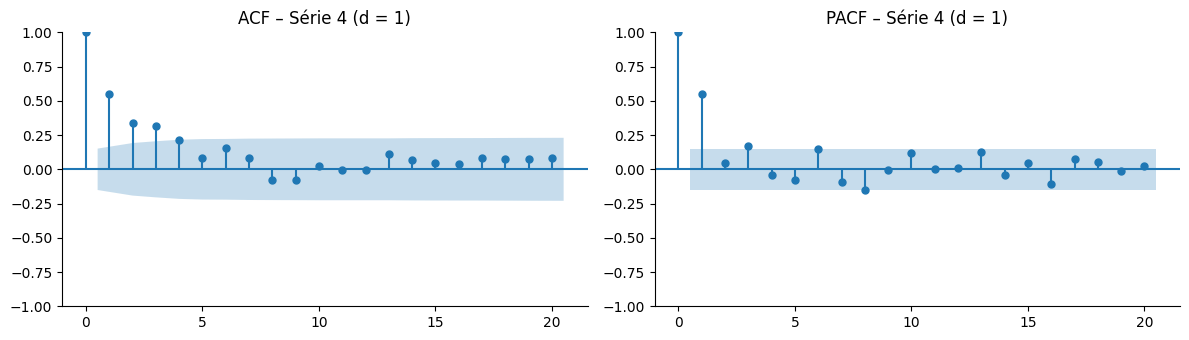

In [17]:
# Uma diferenciação
plt.plot(df4.Yt.diff(), color='tab:red')
plt.gca().set(title='Série Temporal 4 (d = 1)', xlabel='Períodos', ylabel='Demanda'); plt.show()
teste_adf(df4.Yt.diff(), 'Série 4, 1a diferença')
acf_pacf(df4.Yt.diff().dropna(), lags=20, titulo='– Série 4 (d = 1)')

**Metodologia Box-Jenkins:** processo iterativo. Testa-se a estacionariedade (Dickey-Fuller), ajustam-se candidatos (*p*, *d*, *q*), comparam-se AIC/BIC (menor é melhor) e verifica-se a consistência dos resíduos (Ljung-Box-Pierce). Se houver falhas, repete-se variando *p*, *d* e *q*.

> Os slides usam `statsmodels.tsa.arima_model.ARIMA`, removido no statsmodels 0.13. Abaixo, a versão atual: `fit()` sem `disp`, constante via `trend='t'` quando d ≥ 1. Os resultados coincidem com a tabela "Resumo dos Modelos ARIMA".

In [18]:
ordens = [(1,1,0), (0,1,1), (1,1,1), (2,1,0), (2,1,1), (2,1,2)]
linhas = []
for o in ordens:
    fit = ARIMA(df4.Yt, order=o, trend='t').fit()
    linhas.append({'modelo': f'ARIMA{o}', 'AIC': fit.aic, 'BIC': fit.bic,
                   **{k: v for k, v in fit.params.round(4).items() if k != 'sigma2'}})
resumo = pd.DataFrame(linhas).set_index('modelo')
display(resumo.round(4))

,AIC,BIC,x1,ar.L1,ma.L1,ar.L2,ma.L2
modelo,,,,,,,
"ARIMA(1, 1, 0)",392.7892,402.1611,0.4558,0.5522,NaN,NaN,NaN
"ARIMA(0, 1, 1)",404.9921,414.3640,0.4654,NaN,0.4872,NaN,NaN
"ARIMA(1, 1, 1)",393.1730,405.6688,0.4397,0.7245,-0.2548,NaN,NaN
"ARIMA(2, 1, 0)",394.1516,406.6475,0.4509,0.5173,NaN,0.0650,NaN
"ARIMA(2, 1, 1)",394.3560,409.9758,0.4353,0.9876,-0.5019,-0.1628,NaN
"ARIMA(2, 1, 2)",394.2851,413.0289,0.4326,0.5080,0.0083,0.2246,-0.2244


In [19]:
model_fit = ARIMA(df4.Yt, order=(1, 1, 0), trend='t').fit()
print(model_fit.summary())
# x1 = drift (variação média por período):  ΔY_t = 0,4558 + 0,5522 (ΔY_{t-1} - 0,4558)

                               SARIMAX Results                                
Dep. Variable:                     Yt   No. Observations:                  169
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -193.395
Date:                Tue, 20 Oct 2026   AIC                            392.789
Time:                        16:24:36   BIC                            402.161
Sample:                             0   HQIC                           396.593
                                - 169                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.4558      0.139      3.279      0.001       0.183       0.728
ar.L1          0.5522      0.044     12.568      0.000       0.466       0.638
sigma2         0.5841      0.041     14.222      0.0

## 8. Resíduos do modelo e teste de Ljung-Box-Pierce

Um bom modelo deixa resíduos sem estrutura: média ≈ 0, sem autocorrelação, aproximadamente normais.

> Com d = 1, o **primeiro resíduo** do `statsmodels` é um artefato (o próprio $Y_0$) e deve ser descartado.

$$Q_m = n(n+2)\sum_{k=1}^{m}\frac{r_k^2}{n-k}, \qquad \text{rejeitar o modelo se } Q_m > \chi^2_{\alpha,\;m-p-q}$$

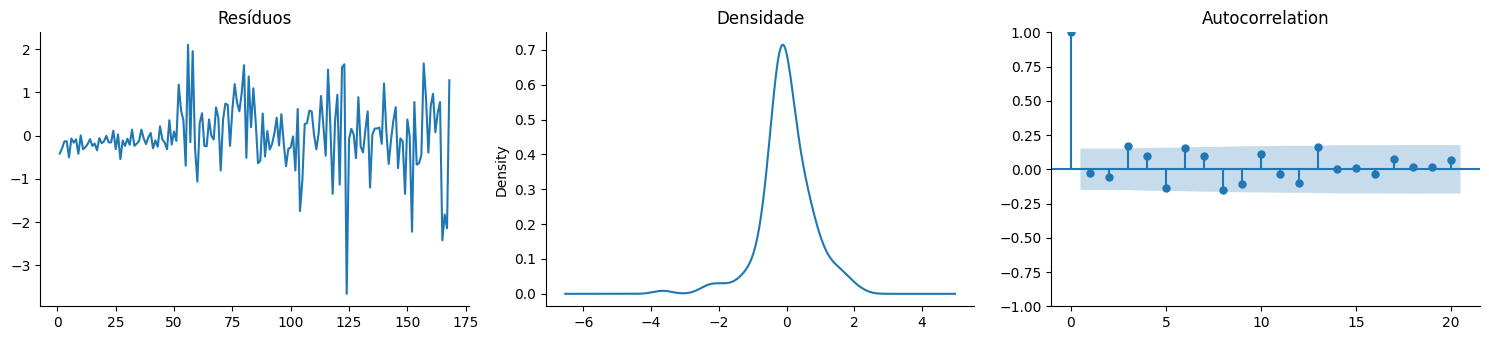

In [20]:
residuals = model_fit.resid[1:]          # descarta o 1º resíduo

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
residuals.plot(ax=ax[0], title='Resíduos')
residuals.plot(kind='kde', ax=ax[1], title='Densidade')
plot_acf(residuals, ax=ax[2], lags=20)
plt.tight_layout(); plt.show()

In [21]:
lb = acorr_ljungbox(residuals, lags=[5, 10, 15, 20], model_df=1)   # model_df = p + q
display(lb.round(4))
# p-valor < α -> rejeita H0 (há autocorrelação nos resíduos)

,lb_stat,lb_pvalue
5,10.4206,0.0339
10,24.7596,0.0032
15,31.7509,0.0043
20,33.9883,0.0184


**Leitura:** a conclusão depende de *m* e de α. A 1%, o modelo passa em m = 5 e 20, mas não em m = 10 e 15; a 5%, é rejeitado em todos. Os resíduos têm variância crescente (gráfico acima). Uma alternativa é modelar o **logaritmo** da série:

In [22]:
fit_log = ARIMA(np.log(df4.Yt), order=(1, 1, 1), trend='t').fit()
display(acorr_ljungbox(fit_log.resid[1:], lags=[10, 20], model_df=2).round(4))

,lb_stat,lb_pvalue
10,14.6591,0.0661
20,20.0870,0.3279


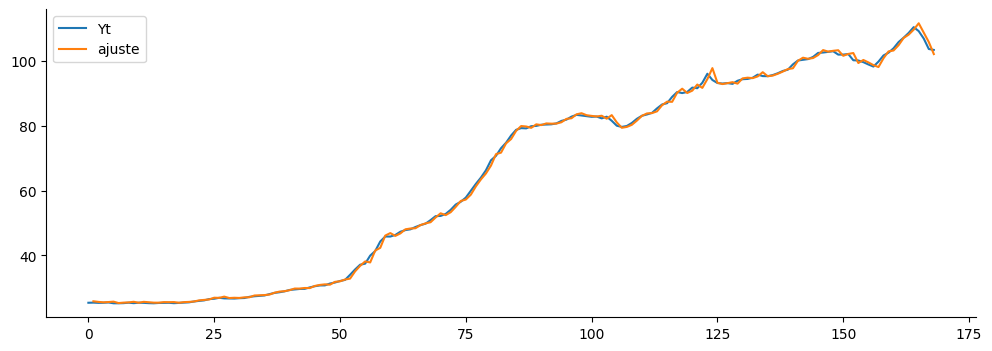

In [23]:
# Dados reais × valores ajustados (previsão 1 passo à frente dentro da amostra)
plt.plot(df4.Yt, label='Yt')
plt.plot(model_fit.fittedvalues[1:], label='ajuste')
plt.legend(); plt.show()

## 9. Treino e teste

AIC/BIC e resíduos medem o ajuste ao **passado**. Só um período de **teste**, reservado e não usado no ajuste, mostra se o modelo prevê bem.

* Divisão **cronológica** (nunca embaralhar): treino = início, teste = final.
* **Previsão de h passos:** prevê todo o teste de uma vez.
* **Previsão rolante de 1 passo (*walk-forward*):** a cada período incorpora o valor real e prevê o seguinte.
* Comparar sempre com o modelo **ingênuo** ($\hat Y_{t+1} = Y_t$).

140 observações de treino; 29 de teste


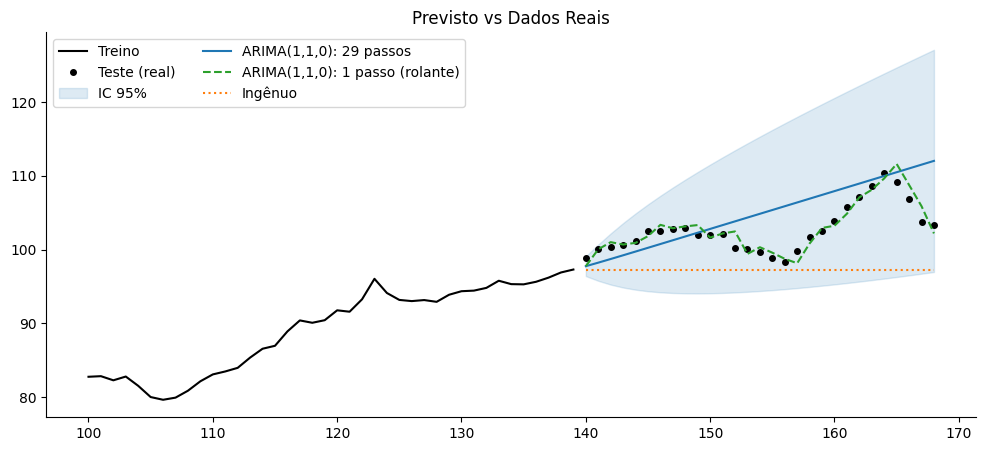

,29 passos,1 passo (rolante),Ingênuo (29 passos)
RMSE,3.99,1.07,6.25
MAE,3.18,0.83,5.40
MAPE (%),3.12,0.81,5.17


In [24]:
train, test = df4.Yt[:140], df4.Yt[140:]
print(len(train), 'observações de treino;', len(test), 'de teste')

model = ARIMA(train, order=(1, 1, 0), trend='t').fit()

# a) Previsão de 29 passos, com IC 95%
prev = model.get_forecast(steps=len(test))
fc, ic = prev.predicted_mean, prev.conf_int(alpha=0.05)

# b) Previsão rolante de 1 passo (parâmetros mantidos)
res, one = model, []
for y in test:
    one.append(res.forecast(1).iloc[0])
    res = res.append([y])
one = pd.Series(one, index=test.index)

ingenuo = pd.Series(train.iloc[-1], index=test.index)

plt.figure(figsize=(12, 5))
plt.plot(train[100:], color='k', label='Treino')
plt.plot(test, 'ko', ms=4, label='Teste (real)')
plt.fill_between(test.index, ic.iloc[:, 0], ic.iloc[:, 1], color='tab:blue', alpha=0.15, label='IC 95%')
plt.plot(fc, color='tab:blue', label='ARIMA(1,1,0): 29 passos')
plt.plot(one, '--', color='tab:green', label='ARIMA(1,1,0): 1 passo (rolante)')
plt.plot(ingenuo, ':', color='tab:orange', label='Ingênuo')
plt.legend(ncol=2); plt.title('Previsto vs Dados Reais'); plt.show()

display(pd.DataFrame({'29 passos': metricas(test, fc), '1 passo (rolante)': metricas(test, one),
                      'Ingênuo (29 passos)': metricas(test, ingenuo)}).round(2))

In [25]:
# Comparação dos candidatos no teste
linhas = []
for o in ordens:
    m = ARIMA(train, order=o, trend='t').fit()
    f = m.forecast(len(test))
    r, um = m, []
    for y in test:
        um.append(r.forecast(1).iloc[0]); r = r.append([y])
    linhas.append({'modelo': f'ARIMA{o}', 'AIC (treino)': m.aic,
                   'RMSE 29 passos': metricas(test, f)['RMSE'], 'RMSE 1 passo': metricas(test, um)['RMSE']})
linhas.append({'modelo': 'Ingênuo', 'AIC (treino)': np.nan,
               'RMSE 29 passos': metricas(test, ingenuo)['RMSE'],
               'RMSE 1 passo': metricas(test, np.r_[train.iloc[-1], test[:-1]])['RMSE']})
display(pd.DataFrame(linhas).set_index('modelo').round(2))

,AIC (treino),RMSE 29 passos,RMSE 1 passo
modelo,,,
"ARIMA(1, 1, 0)",295.23,3.99,1.07
"ARIMA(0, 1, 1)",306.96,4.06,1.10
"ARIMA(1, 1, 1)",288.59,3.77,1.15
"ARIMA(2, 1, 0)",294.54,3.97,1.09
"ARIMA(2, 1, 1)",289.95,3.66,1.14
"ARIMA(2, 1, 2)",289.94,3.63,1.13
Ingênuo,NaN,6.25,1.30


**Conclusões:** todos os ARIMA superam o ingênuo; o erro cresce muito com o horizonte; o menor AIC não garante o menor erro no teste. Entre modelos equivalentes, prefira o mais simples (parcimônia).

### Previsão final
Escolhido o modelo, ele é **reajustado com a série completa** antes de prever: o teste serve para escolher, não para descartar dados.

,previsão,lower Yt,upper Yt
169,103.44,101.95,104.94
170,103.67,100.91,106.44
171,104.00,100.08,107.93
172,104.39,99.43,109.35
173,104.81,98.92,110.69
174,105.24,98.52,111.97
175,105.69,98.20,113.17
176,106.13,97.94,114.32
177,106.59,97.75,115.43
178,107.04,97.59,116.49


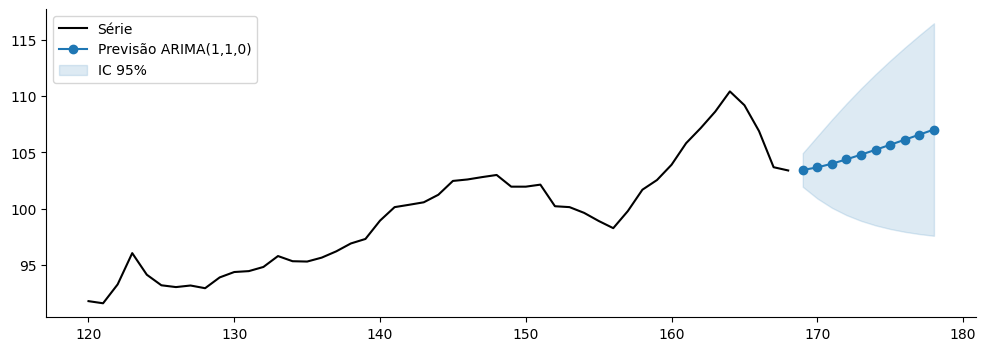

In [26]:
final = ARIMA(df4.Yt, order=(1, 1, 0), trend='t').fit()
prev = final.get_forecast(steps=10)
tab = pd.concat([prev.predicted_mean.rename('previsão'), prev.conf_int(alpha=0.05)], axis=1)
display(tab.round(2))

plt.plot(df4.Yt[120:], color='k', label='Série')
plt.plot(tab['previsão'], 'o-', color='tab:blue', label='Previsão ARIMA(1,1,0)')
plt.fill_between(tab.index, tab.iloc[:, 1], tab.iloc[:, 2], color='tab:blue', alpha=0.15, label='IC 95%')
plt.legend(); plt.show()

## 10. Exercícios

**Exercício 1.** Para os dados abaixo, representativos de um processo de controle de qualidade, identifique um modelo ARIMA(p,d,q) válido e faça a previsão para as próximas 7 medições.

*(Dados na ordem temporal, lidos coluna a coluna da tabela do slide.)*

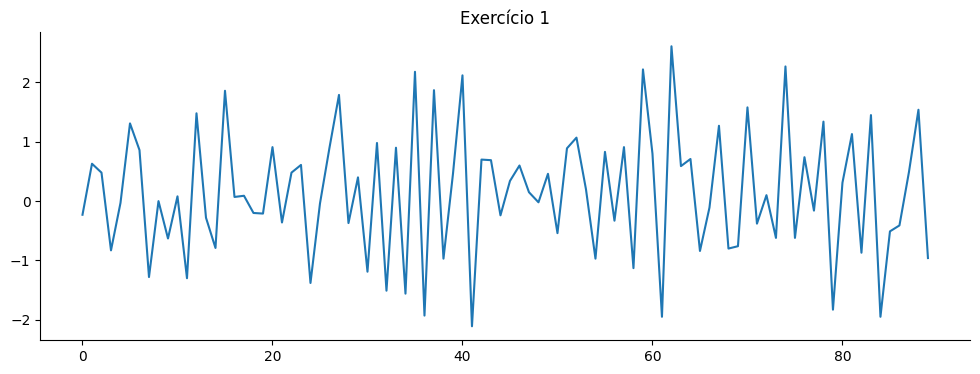

In [27]:
ex1 = pd.Series([
    -0.23, 0.63, 0.48, -0.83, -0.03, 1.31, 0.86, -1.28, 0, -0.63,
    0.08, -1.3, 1.48, -0.28, -0.79, 1.86, 0.07, 0.09, -0.2, -0.21,
    0.91, -0.36, 0.48, 0.61, -1.38, -0.04, 0.9, 1.79, -0.37, 0.4,
    -1.19, 0.98, -1.51, 0.9, -1.56, 2.18, -1.93, 1.87, -0.97, 0.46,
    2.12, -2.11, 0.7, 0.69, -0.24, 0.34, 0.6, 0.15, -0.02, 0.46,
    -0.54, 0.89, 1.07, 0.2, -0.97, 0.83, -0.33, 0.91, -1.13, 2.22,
    0.8, -1.95, 2.61, 0.59, 0.71, -0.84, -0.11, 1.27, -0.8, -0.76,
    1.58, -0.38, 0.1, -0.62, 2.27, -0.62, 0.74, -0.16, 1.34, -1.83,
    0.31, 1.13, -0.87, 1.45, -1.95, -0.51, -0.41, 0.49, 1.54, -0.96])
ex1.plot(title='Exercício 1'); plt.show()

In [28]:
# Sua solução: estacionariedade -> ACF/PACF -> candidatos -> AIC/BIC -> Ljung-Box -> previsão

**Exercício 2.** Para os dados abaixo, indicativos do valor de fechamento das ações de uma empresa de tecnologia nos últimos 65 dias, faça a previsão para os próximos 5 dias usando um modelo ARIMA.

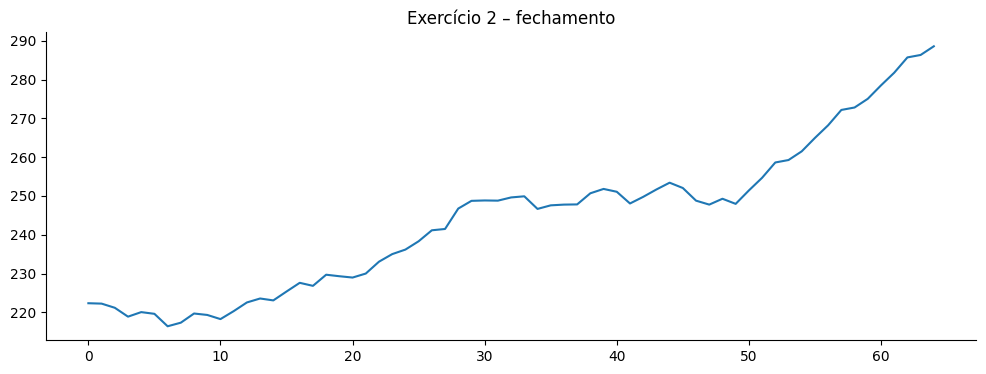

In [29]:
ex2 = pd.Series([
    222.34, 222.24, 221.17, 218.88, 220.05, 219.61, 216.4, 217.33,
    219.69, 219.32, 218.25, 220.3, 222.54, 223.56, 223.07, 225.36,
    227.6, 226.82, 229.69, 229.3, 228.96, 229.99, 233.05, 235,
    236.17, 238.31, 241.14, 241.48, 246.74, 248.73, 248.83, 248.78,
    249.61, 249.9, 246.65, 247.57, 247.76, 247.81, 250.68, 251.8,
    251.07, 248.05, 249.76, 251.66, 253.41, 252.04, 248.78, 247.76,
    249.27, 247.95, 251.41, 254.67, 258.62, 259.25, 261.49, 264.95,
    268.21, 272.16, 272.79, 275.03, 278.49, 281.75, 285.7, 286.33,
    288.57])
ex2.plot(title='Exercício 2 – fechamento'); plt.show()

In [30]:
# Sua solução